**Grid-Search over LAMBDA_DATA & LAMBDA_PHYS**


GRID SEARCH → LAMBDA_DATA=0.10 | LAMBDA_PHYS=0.10
  Adam epoch  200  L_data=7.23e-01  L_phys=4.52e-02
  Adam epoch  400  L_data=6.78e-01  L_phys=4.01e-02
  Adam epoch  600  L_data=6.75e-01  L_phys=3.86e-02
  Adam epoch  800  L_data=6.67e-01  L_phys=3.97e-02
  Adam epoch 1000  L_data=6.67e-01  L_phys=3.32e-02
  Adam epoch 1200  L_data=6.64e-01  L_phys=4.21e-02
  Adam epoch 1400  L_data=6.64e-01  L_phys=2.96e-02
  Adam epoch 1600  L_data=6.63e-01  L_phys=3.51e-02
  Adam epoch 1800  L_data=6.68e-01  L_phys=3.78e-02
  Adam epoch 2000  L_data=6.66e-01  L_phys=3.37e-02
  Adam epoch 2200  L_data=6.65e-01  L_phys=3.43e-02
  Adam epoch 2400  L_data=6.65e-01  L_phys=3.40e-02
  Adam epoch 2600  L_data=6.67e-01  L_phys=3.11e-02
  Adam epoch 2800  L_data=6.68e-01  L_phys=3.38e-02
  Adam epoch 3000  L_data=6.69e-01  L_phys=3.13e-02

GRID SEARCH → LAMBDA_DATA=0.10 | LAMBDA_PHYS=0.30
  Adam epoch  200  L_data=7.68e-01  L_phys=1.42e-02
  Adam epoch  400  L_data=7.26e-01  L_phys=9.55e-03
  Adam epoch  

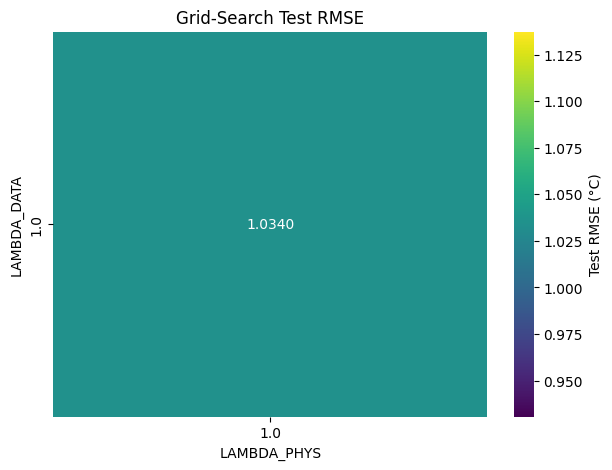


BEST CONFIGURATION
lambda_data    1.000000
lambda_phys    1.000000
test_rmse      1.033968
test_mae       0.859584
Name: 0, dtype: float64
Best model copied → best_model.pt
Full table saved → grid_search_results.csv


In [6]:
# ==============================================================
# PINN + Grid-Search over LAMBDA_DATA & LAMBDA_PHYS
# ==============================================================

import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.autograd import grad
from sklearn.metrics import mean_absolute_error, mean_squared_error
import itertools
import json

# ---------------------- User Settings ----------------------
DATA_PATH = "/kaggle/input/pinn-soil/SoilTemp_Engineering_Completedataset.xlsx"
PORT = 1                                 # 1, 2, or 3
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)

# ---------------------- Fixed hyper-params ----------------------
N_EPOCHS      = 3000
N_COLLOC      = 2000
LR            = 1e-3
USE_LBFGS     = True
PRINT_INTERVAL = 200                     # less noisy during grid-search
SPLIT_RATIO   = 0.8
GRAD_CLIP     = 1.0

# ---------------------- Grid to search ----------------------
LAMBDA_VALUES = [0.1, 0.3, 0.5, 0.7, 1.0]

# ---------------------- Helper functions ----------------------
def sample_collocation(nc, t_min, t_max, w_min, w_max):
    t_s = np.random.uniform(t_min, t_max, (nc,1))
    w_s = np.random.uniform(w_min, w_max, (nc,1))
    return (torch.tensor(t_s, dtype=torch.float32, device=DEVICE, requires_grad=True),
            torch.tensor(w_s, dtype=torch.float32, device=DEVICE))

# ---------------------- Data loading (unchanged) ----------------------
p = Path(DATA_PATH)
if not p.exists():
    raise FileNotFoundError(f"{DATA_PATH} not found")

with open(p, "rb") as f: head = f.read(512)
is_zip = head.startswith(b'PK')
if is_zip:
    df = pd.read_excel(p)
else:
    encodings = ["utf-8", "utf-8-sig", "utf-16", "latin1", "cp1252"]
    df = None
    for enc in encodings:
        try:
            df = pd.read_csv(p, encoding=enc); break
        except: continue
    if df is None: df = pd.read_csv(p, encoding="latin1")

ts_col = next((c for c in df.columns if isinstance(c,str) and ('timestamp' in c.lower() or 'time' in c.lower())), df.columns[0])
other_cols = [c for c in df.columns if c != ts_col]

if len(other_cols) < 9:
    if is_zip: df = pd.read_excel(p, header=1)
    else:      df = pd.read_csv(p, header=1, encoding="latin1")
    ts_col = df.columns[0]; other_cols = [c for c in df.columns if c != ts_col]

num_df = df[[ts_col] + other_cols].copy()
for c in other_cols: num_df[c] = pd.to_numeric(num_df[c], errors='coerce')
num_df = num_df.dropna(subset=other_cols[:9]).reset_index(drop=True)

cols = num_df.columns.tolist()
port_offsets = {1:(1,2,3), 2:(4,5,6), 3:(7,8,9)}
wc_col, t_col = cols[port_offsets[PORT][0]], cols[port_offsets[PORT][1]]

def parse_timestamps(series):
    ts = pd.to_datetime(series, errors='coerce')
    if ts.isna().any():
        ts2 = pd.to_datetime(series, format="%d-%m-%Y %H:%M", errors='coerce')
        if ts2.notna().sum() > ts.notna().sum(): ts = ts2
    if ts.isna().any():
        ts = pd.to_datetime(series, dayfirst=True, errors='coerce')
    if ts.isna().any(): raise ValueError("Timestamp parsing failed")
    return (ts - ts.min()).dt.total_seconds().astype(float), ts

t_seconds, tseries_all = parse_timestamps(num_df[cols[0]])
wc = pd.to_numeric(num_df[wc_col], errors='coerce')
T  = pd.to_numeric(num_df[t_col],  errors='coerce')
valid = (~np.isnan(t_seconds)) & (~np.isnan(wc)) & (~np.isnan(T))
t_np = np.array(t_seconds[valid], dtype=float)
w_np = np.array(wc[valid],        dtype=float)
T_np = np.array(T[valid],         dtype=float)

split_idx = int(SPLIT_RATIO * len(t_np))
t_train_np, t_test_np = t_np[:split_idx], t_np[split_idx:]
w_train_np, w_test_np = w_np[:split_idx], w_np[split_idx:]
T_train_np, T_test_np = T_np[:split_idx], T_np[split_idx:]

# ---------------------- Normalisation ----------------------
t_mean, t_std = t_train_np.mean(), t_train_np.std() + 1e-8
w_mean, w_std = w_train_np.mean(), w_train_np.std() + 1e-8
T_mean, T_std = T_train_np.mean(), T_train_np.std() + 1e-8

t_train_norm = (t_train_np - t_mean) / t_std
w_train_norm = (w_train_np - w_mean) / w_std
T_train_norm = (T_train_np - T_mean) / T_std
t_test_norm  = (t_test_np  - t_mean) / t_std
w_test_norm  = (w_test_np  - w_mean) / w_std
T_test_norm  = (T_test_np  - T_mean) / T_std

# ---------------------- Tensors ----------------------
t_train = torch.tensor(t_train_norm.reshape(-1,1), dtype=torch.float32, device=DEVICE, requires_grad=True)
w_train = torch.tensor(w_train_norm.reshape(-1,1), dtype=torch.float32, device=DEVICE)
T_train = torch.tensor(T_train_norm.reshape(-1,1), dtype=torch.float32, device=DEVICE)

t_test = torch.tensor(t_test_norm.reshape(-1,1), dtype=torch.float32, device=DEVICE, requires_grad=True)
w_test = torch.tensor(w_test_norm.reshape(-1,1), dtype=torch.float32, device=DEVICE)
T_test = torch.tensor(T_test_norm.reshape(-1,1), dtype=torch.float32, device=DEVICE)

# ---------------------- Model classes ----------------------
class PINN_T(nn.Module):
    def __init__(self, hidden=64, layers=4):
        super().__init__()
        seq = [nn.Linear(2, hidden), nn.ReLU()]
        for _ in range(layers-1): seq += [nn.Linear(hidden, hidden), nn.ReLU()]
        seq.append(nn.Linear(hidden, 1))
        self.net = nn.Sequential(*seq)
        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight)
                nn.init.zeros_(m.bias)
    def forward(self, t, w): return self.net(torch.cat([t, w], dim=1))

class ParamKTeq(nn.Module):
    def __init__(self):
        super().__init__()
        self.k0 = nn.Parameter(torch.tensor(0.1))
        self.k1 = nn.Parameter(torch.tensor(0.0))
        self.a  = nn.Parameter(torch.tensor(0.0))
        self.b  = nn.Parameter(torch.tensor(0.0))
    def k_of_w(self, w):  return self.k0 + self.k1 * w
    def Teq_of_w(self, w):return self.a  + self.b  * w

# ---------------------- Physics residual ----------------------
def physics_residual(pinn, phys, t_c, w_c):
    T_hat = pinn(t_c, w_c)
    dTdt  = grad(T_hat, t_c, grad_outputs=torch.ones_like(T_hat),
                 create_graph=True)[0]
    k_w   = phys.k_of_w(w_c)
    Teq_w = phys.Teq_of_w(w_c)
    return dTdt + k_w * (T_hat - Teq_w)

# ---------------------- Grid-search container ----------------------
results = []

# ---------------------- Main grid-search loop ----------------------
for LAMBDA_DATA, LAMBDA_PHYS in itertools.product(LAMBDA_VALUES, LAMBDA_VALUES):
    print("\n" + "="*60)
    print(f"GRID SEARCH → LAMBDA_DATA={LAMBDA_DATA:.2f} | LAMBDA_PHYS={LAMBDA_PHYS:.2f}")
    print("="*60)

    # ---- fresh model for every run ----
    pinn = PINN_T().to(DEVICE)
    phys = ParamKTeq().to(DEVICE)
    optimizer = torch.optim.Adam(list(pinn.parameters()) + list(phys.parameters()), lr=LR)
    mse = nn.MSELoss()
    history = {"L_data": [], "L_phys": [], "L_total": []}

    # ---- Adam training ----
    for ep in range(N_EPOCHS):
        optimizer.zero_grad()
        T_pred = pinn(t_train, w_train)
        L_data = mse(T_pred, T_train)

        t_c, w_c = sample_collocation(N_COLLOC,
                                      t_train_norm.min(), t_train_norm.max(),
                                      w_train_norm.min(), w_train_norm.max())
        r_c = physics_residual(pinn, phys, t_c, w_c)
        L_phys = torch.mean(r_c ** 2)

        L_total = LAMBDA_DATA * L_data + LAMBDA_PHYS * L_phys
        L_total.backward()
        torch.nn.utils.clip_grad_norm_(list(pinn.parameters()) + list(phys.parameters()), max_norm=GRAD_CLIP)
        optimizer.step()

        history["L_data"].append(L_data.item())
        history["L_phys"].append(L_phys.item())
        history["L_total"].append(L_total.item())

        if (ep+1) % PRINT_INTERVAL == 0 or ep == N_EPOCHS-1:
            print(f"  Adam epoch {ep+1:4d}  L_data={L_data.item():.2e}  L_phys={L_phys.item():.2e}")

   # ---- L-BFGS (robust) ----
if USE_LBFGS:
    print("  Starting L-BFGS fine-tuning...")
    # Store raw parameter data (no grad)
    adam_state = {n: p.data.clone() for n, p in
                  list(pinn.named_parameters()) + list(phys.named_parameters())}

    lbfgs = torch.optim.LBFGS(list(pinn.parameters()) + list(phys.parameters()),
                             lr=0.8, max_iter=1000, history_size=100,
                             line_search_fn="strong_wolfe")

    def closure():
        lbfgs.zero_grad()
        Tpred = pinn(t_train, w_train)
        Ld = mse(Tpred, T_train)
        tc, wc = sample_collocation(N_COLLOC,
                                    t_train_norm.min(), t_train_norm.max(),
                                    w_train_norm.min(), w_train_norm.max())
        Lp = torch.mean(physics_residual(pinn, phys, tc, wc) ** 2)
        Lt = LAMBDA_DATA * Ld + LAMBDA_PHYS * Lp
        Lt.backward()
        return Lt

    for i in range(500):
        loss = lbfgs.step(closure)
        if not (torch.isfinite(loss) and loss.item() > 0):
            print(f"   L-BFGS aborted at step {i+1}: loss={loss}")
            break
        if i % 100 == 0 and i > 0:
            print(f"   L-BFGS step {i+1}/500  loss={loss:.2e}")

    # Clamp physics params
    with torch.no_grad():
        phys.k0.clamp_(1e-6, 10.0); phys.k1.clamp_(-10.0, 10.0)
        phys.a .clamp_(-5.0, 5.0); phys.b .clamp_(-10.0, 10.0)

    # Final evaluation
    with torch.no_grad():
        Ld_final = mse(pinn(t_train, w_train), T_train).item()
    tc_f, wc_f = sample_collocation(N_COLLOC,
                                    t_train_norm.min(), t_train_norm.max(),
                                    w_train_norm.min(), w_train_norm.max())
    tc_f.requires_grad_(True)
    with torch.enable_grad():
        r_f = physics_residual(pinn, phys, tc_f, wc_f)
    Lp_final = torch.mean(r_f ** 2).item()

    # Safe fallback if NaN
    if not (np.isfinite(Ld_final) and np.isfinite(Lp_final)):
        print("  L-BFGS produced NaN → safely reverting to Adam weights")
        for n, p in list(pinn.named_parameters()) + list(phys.named_parameters()):
            p.data.copy_(adam_state[n])  # ← This is now safe
        with torch.no_grad():
            Ld_final = mse(pinn(t_train, w_train), T_train).item()
        tc_f, wc_f = sample_collocation(N_COLLOC,
                                        t_train_norm.min(), t_train_norm.max(),
                                        w_train_norm.min(), w_train_norm.max())
        tc_f.requires_grad_(True)
        with torch.enable_grad():
            r_f = physics_residual(pinn, phys, tc_f, wc_f)
        Lp_final = torch.mean(r_f ** 2).item()

    print(f"  L-BFGS final → L_data={Ld_final:.2e}, L_phys={Lp_final:.2e}")

    # ---- Evaluation ----
    pinn.eval(); phys.eval()
    def safe_predict(t, w):
        with torch.no_grad():
            out = pinn(t, w).cpu().numpy()
            if np.any(np.isnan(out)):
                out = np.nan_to_num(out, nan=0.0)
            return out * T_std + T_mean

    T_pred_train = safe_predict(t_train, w_train).flatten()
    T_pred_test  = safe_predict(t_test,  w_test).flatten()

    # metrics
    train_mae  = mean_absolute_error(T_train_np[:split_idx], T_pred_train)
    train_rmse = np.sqrt(mean_squared_error(T_train_np[:split_idx], T_pred_train))
    test_mae   = mean_absolute_error(T_test_np, T_pred_test)
    test_rmse  = np.sqrt(mean_squared_error(T_test_np, T_pred_test))

    # physics residual (denorm approx)
    r_train = physics_residual(pinn, phys, t_train, w_train).detach()
    mean_abs_r_train = torch.mean(torch.abs(r_train)).item() * T_std / t_std
    r_test  = physics_residual(pinn, phys, t_test,  w_test).detach()
    mean_abs_r_test  = torch.mean(torch.abs(r_test)).item() * T_std / t_std

    # ---- Store result ----
    result = {
        "lambda_data": LAMBDA_DATA,
        "lambda_phys": LAMBDA_PHYS,
        "train_mae": train_mae,
        "train_rmse": train_rmse,
        "test_mae": test_mae,
        "test_rmse": test_rmse,
        "phys_loss": Lp_final,
        "mean_abs_r_train": mean_abs_r_train,
        "mean_abs_r_test": mean_abs_r_test,
        "k0": phys.k0.item(),
        "k1": phys.k1.item(),
        "a":  phys.a.item(),
        "b":  phys.b.item()
    }
    results.append(result)

    # ---- Save model ----
    save_name = f"pinn_port{PORT}_lambdaD_{LAMBDA_DATA:.2f}_lambdaP_{LAMBDA_PHYS:.2f}.pt"
    torch.save({
        'pinn': pinn.state_dict(),
        'phys': phys.state_dict(),
        'scalers': {'t_mean': t_mean, 't_std': t_std,
                    'w_mean': w_mean, 'w_std': w_std,
                    'T_mean': T_mean, 'T_std': T_std},
        'hyper': {'lambda_data': LAMBDA_DATA, 'lambda_phys': LAMBDA_PHYS}
    }, save_name)

    print(f"  → Test RMSE = {test_rmse:.4f} °C   (saved as {save_name})")

# ---------------------- Summary ----------------------
df_res = pd.DataFrame(results)
print("\n=== GRID-SEARCH SUMMARY ===")
print(df_res[['lambda_data','lambda_phys','test_rmse','test_mae','phys_loss']].round(4))

# ----- Heat-map of test RMSE -----
pivot = df_res.pivot(index='lambda_data', columns='lambda_phys', values='test_rmse')
plt.figure(figsize=(7,5))
import seaborn as sns
sns.heatmap(pivot, annot=True, fmt=".4f", cmap="viridis", cbar_kws={'label':'Test RMSE (°C)'})
plt.title("Grid-Search Test RMSE")
plt.xlabel("LAMBDA_PHYS")
plt.ylabel("LAMBDA_DATA")
plt.show()

# ----- Best model -----
best_row = df_res.loc[df_res['test_rmse'].idxmin()]
print("\nBEST CONFIGURATION")
print(best_row[['lambda_data','lambda_phys','test_rmse','test_mae']])

# copy best model to a single file
best_path = f"pinn_port{PORT}_lambdaD_{best_row['lambda_data']:.2f}_lambdaP_{best_row['lambda_phys']:.2f}.pt"
os.system(f"cp {best_path} best_model.pt")
print(f"Best model copied → best_model.pt")

# ----- Save full results -----
df_res.to_csv("grid_search_results.csv", index=False)
print("Full table saved → grid_search_results.csv")

**PORT1**

Detected Excel — reading with pd.read_excel()
Columns preview: ['z6-18732', 'Port 1', 'Port 1.1', 'Port 1.2', 'Port 2', 'Port 2.1', 'Port 2.2', 'Port 3', 'Port 3.1', 'Port 3.2', 'Port 7', 'Port 7.1', 'Port 8', 'Port 8.1']


,z6-18732,Port 1,Port 1.1,Port 1.2,Port 2,Port 2.1,Port 2.2,Port 3,Port 3.1,Port 3.2,Port 7,Port 7.1,Port 8,Port 8.1
0,Records: 87288,TEROS 12,TEROS 12,TEROS 12,TEROS 12,TEROS 12,TEROS 12,TEROS 12,TEROS 12,TEROS 12,Battery,Battery,Barometer,Barometer
1,Timestamp,m³/m³ Water Content,°C Soil Temperature,mS/cm Bulk EC,m³/m³ Water Content,°C Soil Temperature,mS/cm Bulk EC,m³/m³ Water Content,°C Soil Temperature,mS/cm Bulk EC,% Battery Percent,mV Battery Voltage,kPa Reference Pressure,°C Logger Temperature
2,2022-08-18 12:30:00,0.18214,29.67,0.004198,0.12795,29.3,0.002931,0.234158,29.93,0.053703,100,7805,100.78,33.2
3,2022-08-18 12:45:00,0.188928,29.65,0.004797,0.127912,29.39,0.002931,0.232257,29.9,0.055081,100,7814,100.76,33.62
4,2022-08-18 13:00:00,0.193389,29.75,0.004797,0.127757,29.53,0.002931,0.230938,29.9,0.055847,100,7833,100.72,33.97


Using timestamp: z6-18732
Clean rows: 101398
Port 1: WC=Port 1, T=Port 1.1
Prepared: 101398 samples for Port 1
Train: 81118 pts (80%), Test: 20280 pts
Params count: 12741
Training on cuda


/usr/local/lib/python3.11/dist-packages/torch/autograd/graph.py:823: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:180.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Epoch 1/3000 L_data=9.620e-01 L_phys=6.250e-03 L_total=9.683e-01
Epoch 101/3000 L_data=7.622e-01 L_phys=2.498e-02 L_total=7.872e-01
Epoch 201/3000 L_data=7.408e-01 L_phys=2.730e-02 L_total=7.681e-01
Epoch 301/3000 L_data=7.020e-01 L_phys=3.245e-02 L_total=7.345e-01
Epoch 401/3000 L_data=6.799e-01 L_phys=3.417e-02 L_total=7.140e-01
Epoch 501/3000 L_data=6.755e-01 L_phys=3.286e-02 L_total=7.084e-01
Epoch 601/3000 L_data=6.713e-01 L_phys=3.012e-02 L_total=7.014e-01
Epoch 701/3000 L_data=6.725e-01 L_phys=2.561e-02 L_total=6.981e-01
Epoch 801/3000 L_data=6.688e-01 L_phys=3.215e-02 L_total=7.009e-01
Epoch 901/3000 L_data=6.665e-01 L_phys=3.598e-02 L_total=7.025e-01
Epoch 1001/3000 L_data=6.638e-01 L_phys=3.167e-02 L_total=6.954e-01
Epoch 1101/3000 L_data=6.604e-01 L_phys=3.364e-02 L_total=6.940e-01
Epoch 1201/3000 L_data=6.595e-01 L_phys=3.506e-02 L_total=6.945e-01
Epoch 1301/3000 L_data=6.581e-01 L_phys=3.281e-02 L_total=6.909e-01
Epoch 1401/3000 L_data=6.559e-01 L_phys=3.469e-02 L_total=6.

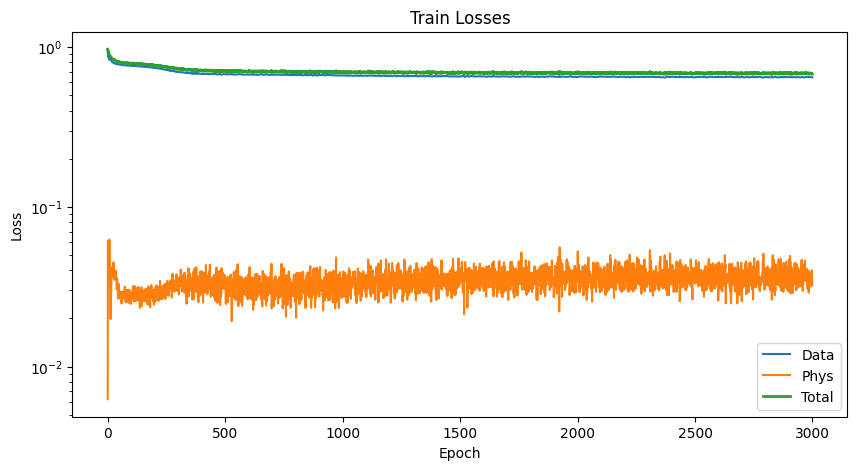

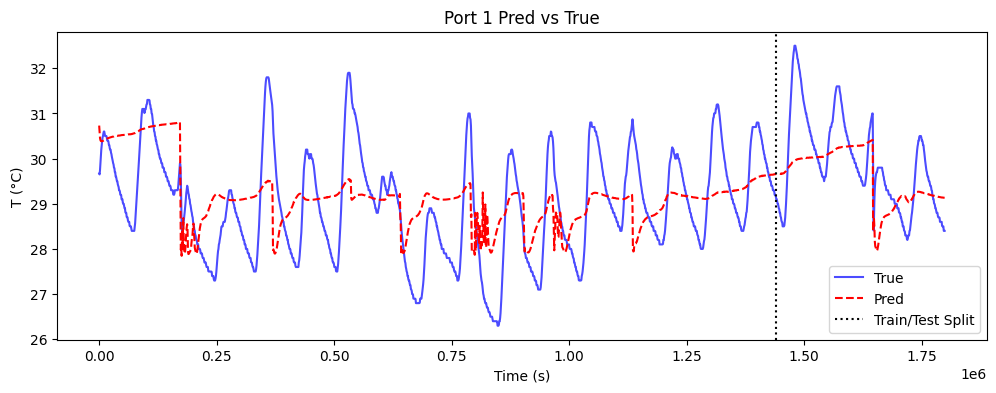

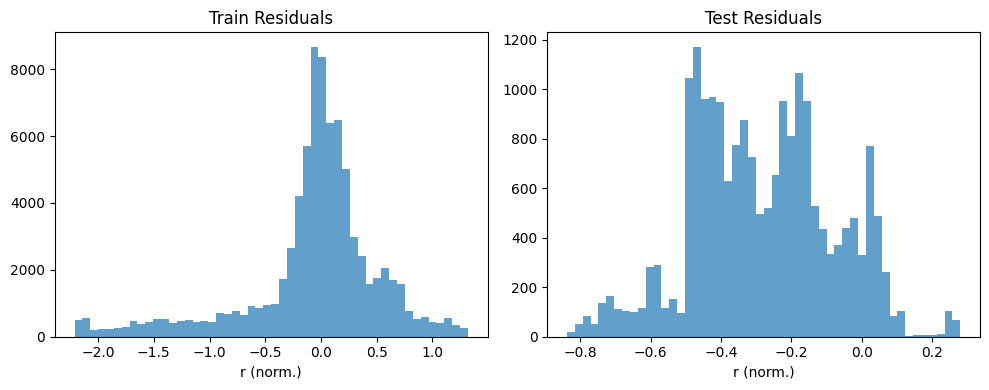

Saved to pinn_port1_split.pt


,timestamp,w,T_true,T_pred
0,2024-12-10 12:15:00,0.296726,28.10,29.478146
1,2024-12-10 12:30:00,0.296532,28.15,29.487202
2,2024-12-10 12:45:00,0.296454,28.20,29.491556
3,2024-12-10 13:00:00,0.296222,28.29,29.507036
4,2024-12-10 13:15:00,0.296028,28.35,29.522543


Test preds saved as predictions_port{PORT}_test.csv


In [1]:
# Fixed PINN Notebook: Train/Test Split + Residual Eval (No no_grad for Physics)
# Bug Fix: Residual computation needs grad_fn—compute without no_grad, detach for metrics.
# Run for Port 1 (change PORT for 2/3). Outputs train/test metrics, residuals on both.

import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.autograd import grad
from sklearn.metrics import mean_absolute_error, mean_squared_error

# ---------------------- User Settings ----------------------
DATA_PATH = "/kaggle/input/pinn-soil/SoilTemp_Engineering_Completedataset.xlsx"
PORT = 1  # 1, 2, or 3
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)

# Hyperparams
N_EPOCHS = 3000
N_COLLOC = 2000
LR = 1e-3
LAMBDA_PHYS = 1.0
USE_LBFGS = True
PRINT_INTERVAL = 100
SPLIT_RATIO = 0.8  # 80% train, 20% test

# -----------------------------------------------------------
p = Path(DATA_PATH)
if not p.exists():
    raise FileNotFoundError(f"{DATA_PATH} not found. CWD: {os.getcwd()}")

# Robust Loader (unchanged)
with open(p, "rb") as f:
    head = f.read(512)
is_zip = head.startswith(b'PK')
if is_zip:
    print("Detected Excel — reading with pd.read_excel()")
    df = pd.read_excel(p)
else:
    print("Detected CSV — robust read")
    encodings_try = ["utf-8", "utf-8-sig", "utf-16", "latin1", "cp1252"]
    df = None
    for enc in encodings_try:
        try:
            df_try = pd.read_csv(p, encoding=enc)
            df = df_try; print(f"CSV with {enc}"); break
        except: continue
    if df is None: df = pd.read_csv(p, encoding="latin1")

print("Columns preview:", df.columns.tolist()[:20])
display(df.head())

# Find timestamp
ts_col = next((c for c in df.columns if isinstance(c, str) and ('timestamp' in c.lower() or 'time' in c.lower())), df.columns[0])
print("Using timestamp:", ts_col)
other_cols = [c for c in df.columns if c != ts_col]
if len(other_cols) < 9:
    try:
        if is_zip: df = pd.read_excel(p, header=1)
        else: df = pd.read_csv(p, header=1, encoding="latin1")
        print("Re-read with header=1")
        display(df.head()); ts_col = df.columns[0]; other_cols = [c for c in df.columns if c != ts_col]
    except: pass

# Numeric conversion & clean
num_df = df[[ts_col] + other_cols].copy()
for c in other_cols: num_df[c] = pd.to_numeric(num_df[c], errors='coerce')
if len(other_cols) < 9: raise ValueError(f"Need 9+ cols after ts; found {len(other_cols)}")
num_df = num_df.dropna(subset=other_cols[:9]).reset_index(drop=True)
print(f"Clean rows: {num_df.shape[0]}")

# Port columns
cols = num_df.columns.tolist()
port_offsets = {1: (1,2,3), 2: (4,5,6), 3: (7,8,9)}
wc_col, t_col = cols[port_offsets[PORT][0]], cols[port_offsets[PORT][1]]
print(f"Port {PORT}: WC={wc_col}, T={t_col}")

# Parse ts
def parse_timestamps(series):
    try: ts = pd.to_datetime(series, errors='coerce')
    except: ts = pd.to_datetime(series, errors='coerce')
    if ts.isna().any():
        ts2 = pd.to_datetime(series, format="%d-%m-%Y %H:%M", errors='coerce')
        if ts2.notna().sum() > ts.notna().sum(): ts = ts2
    if ts.isna().any(): ts = pd.to_datetime(series, dayfirst=True, errors='coerce')
    if ts.isna().any(): raise ValueError("TS parse failed")
    seconds = (ts - ts.min()).dt.total_seconds().astype(float)
    return seconds, ts

t_seconds, tseries_all = parse_timestamps(num_df[cols[0]])
wc = pd.to_numeric(num_df[wc_col], errors='coerce')
T = pd.to_numeric(num_df[t_col], errors='coerce')
valid_mask = (~np.isnan(t_seconds)) & (~np.isnan(wc)) & (~np.isnan(T))
t_seconds = pd.Series(t_seconds)[valid_mask].reset_index(drop=True)
wc = wc[valid_mask].reset_index(drop=True)
T = T[valid_mask].reset_index(drop=True)
t_np = np.array(t_seconds, dtype=float)
w_np = np.array(wc, dtype=float)
T_np = np.array(T, dtype=float)
print(f"Prepared: {len(t_np)} samples for Port {PORT}")

# ----------------- Train/Test Split (Chronological) -----------------
split_idx = int(SPLIT_RATIO * len(t_np))
t_train_np, t_test_np = t_np[:split_idx], t_np[split_idx:]
w_train_np, w_test_np = w_np[:split_idx], w_np[split_idx:]
T_train_np, T_test_np = T_np[:split_idx], T_np[split_idx:]

print(f"Train: {len(t_train_np)} pts ({SPLIT_RATIO*100:.0f}%), Test: {len(t_test_np)} pts")

# Normalize ON TRAIN ONLY
t_mean, t_std = t_train_np.mean(), t_train_np.std() + 1e-8
w_mean, w_std = w_train_np.mean(), w_train_np.std() + 1e-8
T_mean, T_std = T_train_np.mean(), T_train_np.std() + 1e-8

t_train_norm = (t_train_np - t_mean) / t_std
w_train_norm = (w_train_np - w_mean) / w_std
T_train_norm = (T_train_np - T_mean) / T_std

t_test_norm = (t_test_np - t_mean) / t_std
w_test_norm = (w_test_np - w_mean) / w_std
T_test_norm = (T_test_np - T_mean) / T_std

# Tensors (requires_grad=True for t_train/t_test for residuals)
t_train = torch.tensor(t_train_norm.reshape(-1,1), dtype=torch.float32, device=DEVICE, requires_grad=True)
w_train = torch.tensor(w_train_norm.reshape(-1,1), dtype=torch.float32, device=DEVICE)
T_train = torch.tensor(T_train_norm.reshape(-1,1), dtype=torch.float32, device=DEVICE)

t_test = torch.tensor(t_test_norm.reshape(-1,1), dtype=torch.float32, device=DEVICE, requires_grad=True)
w_test = torch.tensor(w_test_norm.reshape(-1,1), dtype=torch.float32, device=DEVICE)
T_test = torch.tensor(T_test_norm.reshape(-1,1), dtype=torch.float32, device=DEVICE)

# Collocations from TRAIN domain
def sample_collocation(nc):
    t_s = np.random.uniform(t_train_norm.min(), t_train_norm.max(), (nc,1))
    w_s = np.random.uniform(w_train_norm.min(), w_train_norm.max(), (nc,1))
    return (torch.tensor(t_s, dtype=torch.float32, device=DEVICE, requires_grad=True),
            torch.tensor(w_s, dtype=torch.float32, device=DEVICE))

# Save scalers
np.savez('scalers.npz', t_mean=t_mean, t_std=t_std, w_mean=w_mean, w_std=w_std, T_mean=T_mean, T_std=T_std)

# ----------------- Model -----------------
class PINN_T(nn.Module):
    def __init__(self, in_dim=2, hidden=64, layers=4):
        super().__init__()
        seq = [nn.Linear(in_dim, hidden), nn.Tanh()]
        for _ in range(layers-1): seq += [nn.Linear(hidden, hidden), nn.Tanh()]
        seq.append(nn.Linear(hidden,1))
        self.net = nn.Sequential(*seq)
        for m in self.net:
            if isinstance(m, nn.Linear): nn.init.xavier_normal_(m.weight); nn.init.zeros_(m.bias)
    def forward(self, t, w): return self.net(torch.cat([t, w], dim=1))

class ParamKTeq(nn.Module):
    def __init__(self): super().__init__(); self.k0 = nn.Parameter(torch.tensor(0.1)); self.k1 = nn.Parameter(torch.tensor(0.0)); self.a = nn.Parameter(torch.tensor(0.0)); self.b = nn.Parameter(torch.tensor(0.0))
    def k_of_w(self, w): return self.k0 + self.k1 * w
    def Teq_of_w(self, w): return self.a + self.b * w

pinn = PINN_T().to(DEVICE)
phys = ParamKTeq().to(DEVICE)
print("Params count:", sum(p.numel() for p in pinn.parameters()) + sum(p.numel() for p in phys.parameters()))

# Loss & Optimizer
mse = nn.MSELoss()
optimizer = torch.optim.Adam(list(pinn.parameters()) + list(phys.parameters()), lr=LR)
history = {"L_data": [], "L_phys": [], "L_total": []}

def physics_residual(t_colloc, w_colloc):
    T_hat = pinn(t_colloc, w_colloc)
    dTdt = grad(T_hat, t_colloc, grad_outputs=torch.ones_like(T_hat), create_graph=True)[0]
    k_w = phys.k_of_w(w_colloc); Teq_w = phys.Teq_of_w(w_colloc)
    return dTdt + k_w * (T_hat - Teq_w)

# ----------------- Training on TRAIN -----------------
print("Training on", DEVICE)
for ep in range(N_EPOCHS):
    optimizer.zero_grad()
    T_pred_train = pinn(t_train, w_train)
    L_data = mse(T_pred_train, T_train)
    t_c, w_c = sample_collocation(N_COLLOC)
    r_c = physics_residual(t_c, w_c)
    L_phys = torch.mean(r_c**2)
    L_total = L_data + LAMBDA_PHYS * L_phys
    L_total.backward()
    optimizer.step()
    history["L_data"].append(L_data.item()); history["L_phys"].append(L_phys.item()); history["L_total"].append(L_total.item())
    if (ep % PRINT_INTERVAL == 0) or (ep == N_EPOCHS-1):
        print(f"Epoch {ep+1}/{N_EPOCHS} L_data={L_data.item():.3e} L_phys={L_phys.item():.3e} L_total={L_total.item():.3e}")

# LBFGS on TRAIN
if USE_LBFGS:
    print("L-BFGS fine-tune...")
    lbfgs = torch.optim.LBFGS(list(pinn.parameters()) + list(phys.parameters()), lr=1.0, max_iter=500, history_size=50)
    def closure(): lbfgs.zero_grad(); Tpred = pinn(t_train, w_train); Ld = mse(Tpred, T_train); tc, wc = sample_collocation(N_COLLOC); Lp = torch.mean(physics_residual(tc, wc)**2); Lt = Ld + LAMBDA_PHYS * Lp; Lt.backward(); return Lt
    lbfgs.step(closure)
    with torch.no_grad(): Ld_final = mse(pinn(t_train, w_train), T_train).item()
    tc_f, wc_f = sample_collocation(N_COLLOC); Lp_final = torch.mean(physics_residual(tc_f, wc_f)**2).item()
    print(f"L-BFGS: L_data={Ld_final:.3e}, L_phys={Lp_final:.3e}")

# ----------------- Evaluation: TRAIN & TEST -----------------
pinn.eval(); phys.eval()

# Predictions (with no_grad for efficiency)
with torch.no_grad():
    T_pred_train_norm = pinn(t_train, w_train).cpu().numpy()
    T_pred_train = T_pred_train_norm * T_std + T_mean
    t_train_plot = t_train.detach().cpu().numpy() * t_std + t_mean

    T_pred_test_norm = pinn(t_test, w_test).cpu().numpy()
    T_pred_test = T_pred_test_norm * T_std + T_mean
    t_test_plot = t_test.detach().cpu().numpy() * t_std + t_mean

# Metrics
train_mae = mean_absolute_error(T_train_np[:split_idx], T_pred_train.flatten())
train_rmse = np.sqrt(mean_squared_error(T_train_np[:split_idx], T_pred_train.flatten()))
test_mae = mean_absolute_error(T_test_np, T_pred_test.flatten())
test_rmse = np.sqrt(mean_squared_error(T_test_np, T_pred_test.flatten()))

print(f"\nTrain MAE/RMSE: {train_mae:.4f}/{train_rmse:.4f} °C")
print(f"Test MAE/RMSE: {test_mae:.4f}/{test_rmse:.4f} °C")

# Physics Residuals (NO no_grad; detach for metrics)
r_train = physics_residual(t_train, w_train).detach()
mean_abs_r_train = torch.mean(torch.abs(r_train)).item() * T_std / t_std  # Denorm approx °C/h
r_test = physics_residual(t_test, w_test).detach()
mean_abs_r_test = torch.mean(torch.abs(r_test)).item() * T_std / t_std
print(f"Train Mean |r| (denorm approx.): {mean_abs_r_train:.4f} °C/h")
print(f"Test Mean |r| (denorm approx.): {mean_abs_r_test:.4f} °C/h")

# Learned Params
k0, k1 = phys.k0.item(), phys.k1.item()
a, b = phys.a.item(), phys.b.item()
print(f"\nParams (norm.): k(w)={k0:.6e} + {k1:.6e} w; T_eq(w)={a:.6e} + {b:.6e} w")

# ----------------- Plots -----------------
# Losses
plt.figure(figsize=(10,5)); plt.semilogy(history["L_data"], label="Data"); plt.semilogy(history["L_phys"], label="Phys"); plt.semilogy(history["L_total"], label="Total", lw=2)
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.title("Train Losses"); plt.show()

# Time Series (Train + Test)
Nplot = min(2000, len(t_train_plot) + len(t_test_plot))
t_full_plot = np.concatenate([t_train_plot.flatten(), t_test_plot.flatten()])
T_true_full = np.concatenate([T_train_np[:split_idx], T_test_np])
T_pred_full = np.concatenate([T_pred_train.flatten(), T_pred_test.flatten()])
sort_idx = np.argsort(t_full_plot)
plt.figure(figsize=(12,4))
plt.plot(t_full_plot[sort_idx][:Nplot], T_true_full[sort_idx][:Nplot], 'b-', label="True", alpha=0.7)
plt.plot(t_full_plot[sort_idx][:Nplot], T_pred_full[sort_idx][:Nplot], 'r--', label="Pred")
plt.axvline(t_full_plot[sort_idx][int(SPLIT_RATIO * Nplot)], color='k', ls=':', label="Train/Test Split")
plt.xlabel("Time (s)"); plt.ylabel("T (°C)"); plt.legend(); plt.title(f"Port {PORT} Pred vs True"); plt.show()

# Residuals Plot (Train vs Test)
plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.hist(r_train.cpu().numpy().flatten(), bins=50, alpha=0.7, label="Train"); plt.title("Train Residuals"); plt.xlabel("r (norm.)")
plt.subplot(1,2,2); plt.hist(r_test.cpu().numpy().flatten(), bins=50, alpha=0.7, label="Test"); plt.title("Test Residuals"); plt.xlabel("r (norm.)")
plt.tight_layout(); plt.show()

# Save
SAVE_PATH = f"pinn_port{PORT}_split.pt"
torch.save({'pinn': pinn.state_dict(), 'phys': phys.state_dict(), 'scalers': {'t_mean': t_mean, 't_std': t_std, 'w_mean': w_mean, 'w_std': w_std, 'T_mean': T_mean, 'T_std': T_std}}, SAVE_PATH)
print(f"Saved to {SAVE_PATH}")

# Test DF
test_df = pd.DataFrame({'timestamp': tseries_all.iloc[split_idx:].reset_index(drop=True), 'w': w_test_np, 'T_true': T_test_np, 'T_pred': T_pred_test.flatten()})
display(test_df.head())
test_df.to_csv(f'predictions_port{PORT}_test.csv', index=False)
print("Test preds saved as predictions_port{PORT}_test.csv")

**PORT2**

Detected Excel — reading with pd.read_excel()
Columns preview: ['z6-18732', 'Port 1', 'Port 1.1', 'Port 1.2', 'Port 2', 'Port 2.1', 'Port 2.2', 'Port 3', 'Port 3.1', 'Port 3.2', 'Port 7', 'Port 7.1', 'Port 8', 'Port 8.1']


,z6-18732,Port 1,Port 1.1,Port 1.2,Port 2,Port 2.1,Port 2.2,Port 3,Port 3.1,Port 3.2,Port 7,Port 7.1,Port 8,Port 8.1
0,Records: 87288,TEROS 12,TEROS 12,TEROS 12,TEROS 12,TEROS 12,TEROS 12,TEROS 12,TEROS 12,TEROS 12,Battery,Battery,Barometer,Barometer
1,Timestamp,m³/m³ Water Content,°C Soil Temperature,mS/cm Bulk EC,m³/m³ Water Content,°C Soil Temperature,mS/cm Bulk EC,m³/m³ Water Content,°C Soil Temperature,mS/cm Bulk EC,% Battery Percent,mV Battery Voltage,kPa Reference Pressure,°C Logger Temperature
2,2022-08-18 12:30:00,0.18214,29.67,0.004198,0.12795,29.3,0.002931,0.234158,29.93,0.053703,100,7805,100.78,33.2
3,2022-08-18 12:45:00,0.188928,29.65,0.004797,0.127912,29.39,0.002931,0.232257,29.9,0.055081,100,7814,100.76,33.62
4,2022-08-18 13:00:00,0.193389,29.75,0.004797,0.127757,29.53,0.002931,0.230938,29.9,0.055847,100,7833,100.72,33.97


Using timestamp: z6-18732
Clean rows: 101398
Port 2: WC=Port 2, T=Port 2.1
Prepared: 101398 samples for Port 2
Train: 81118 pts (80%), Test: 20280 pts
Params count: 12741
Training on cuda
Epoch 1/3000 L_data=9.477e-01 L_phys=6.595e-03 L_total=9.543e-01
Epoch 101/3000 L_data=7.150e-01 L_phys=3.828e-02 L_total=7.533e-01
Epoch 201/3000 L_data=6.997e-01 L_phys=4.035e-02 L_total=7.400e-01
Epoch 301/3000 L_data=6.747e-01 L_phys=3.383e-02 L_total=7.085e-01
Epoch 401/3000 L_data=6.576e-01 L_phys=3.117e-02 L_total=6.888e-01
Epoch 501/3000 L_data=6.556e-01 L_phys=2.926e-02 L_total=6.848e-01
Epoch 601/3000 L_data=6.518e-01 L_phys=3.335e-02 L_total=6.852e-01
Epoch 701/3000 L_data=6.518e-01 L_phys=2.541e-02 L_total=6.772e-01
Epoch 801/3000 L_data=6.476e-01 L_phys=3.156e-02 L_total=6.791e-01
Epoch 901/3000 L_data=6.465e-01 L_phys=3.475e-02 L_total=6.813e-01
Epoch 1001/3000 L_data=6.459e-01 L_phys=2.788e-02 L_total=6.738e-01
Epoch 1101/3000 L_data=6.435e-01 L_phys=3.683e-02 L_total=6.804e-01
Epoch 12

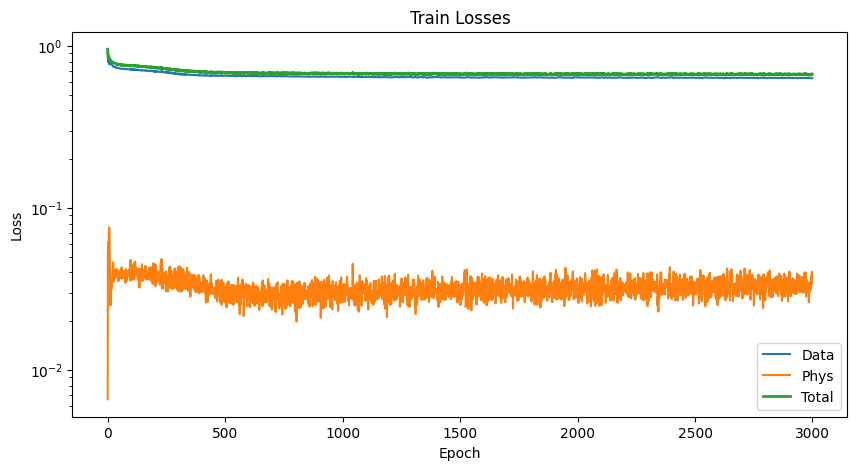

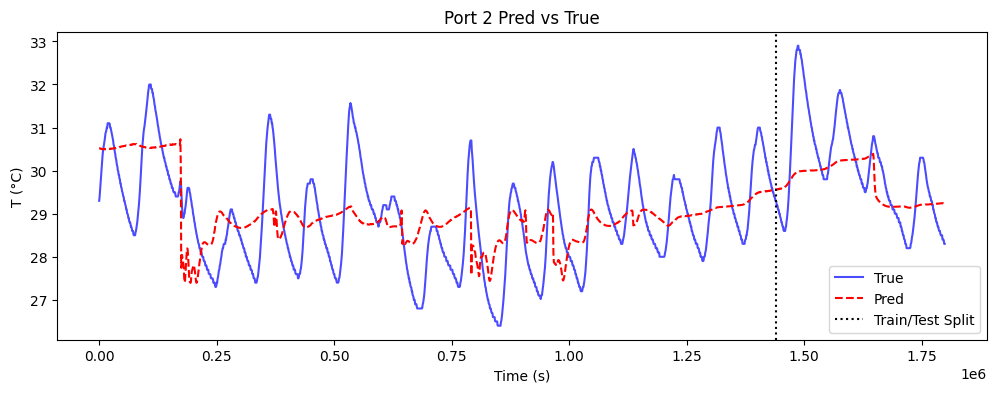

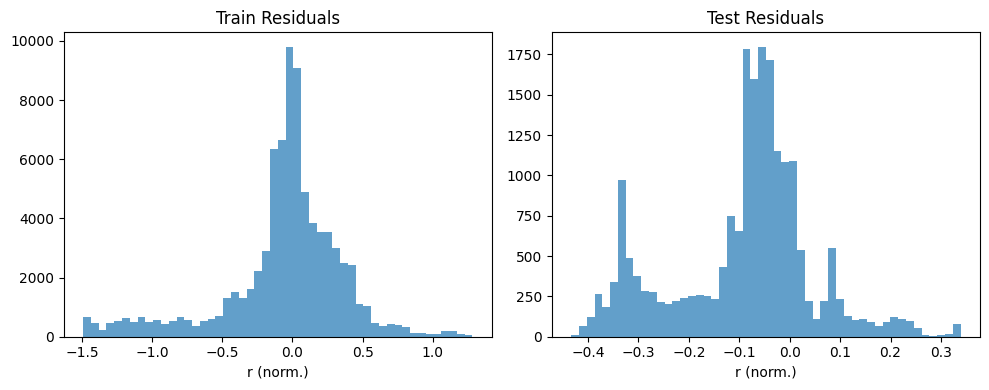

Saved to pinn_port2_split.pt


,timestamp,w,T_true,T_pred
0,2024-12-10 12:15:00,0.284662,28.15,30.012747
1,2024-12-10 12:30:00,0.283692,28.20,29.984808
2,2024-12-10 12:45:00,0.283498,28.20,29.979036
3,2024-12-10 13:00:00,0.283304,28.23,29.973213
4,2024-12-10 13:15:00,0.283149,28.30,29.968519


Test preds saved as predictions_port{PORT}_test.csv


In [2]:
# Fixed PINN Notebook: Train/Test Split + Residual Eval (No no_grad for Physics)
# Bug Fix: Residual computation needs grad_fn—compute without no_grad, detach for metrics.
# Run for Port 1 (change PORT for 2/3). Outputs train/test metrics, residuals on both.

import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.autograd import grad
from sklearn.metrics import mean_absolute_error, mean_squared_error

# ---------------------- User Settings ----------------------
DATA_PATH = "/kaggle/input/pinn-soil/SoilTemp_Engineering_Completedataset.xlsx"
PORT = 2  # 1, 2, or 3
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)

# Hyperparams
N_EPOCHS = 3000
N_COLLOC = 2000
LR = 1e-3
LAMBDA_PHYS = 1.0
USE_LBFGS = True
PRINT_INTERVAL = 100
SPLIT_RATIO = 0.8  # 80% train, 20% test

# -----------------------------------------------------------
p = Path(DATA_PATH)
if not p.exists():
    raise FileNotFoundError(f"{DATA_PATH} not found. CWD: {os.getcwd()}")

# Robust Loader (unchanged)
with open(p, "rb") as f:
    head = f.read(512)
is_zip = head.startswith(b'PK')
if is_zip:
    print("Detected Excel — reading with pd.read_excel()")
    df = pd.read_excel(p)
else:
    print("Detected CSV — robust read")
    encodings_try = ["utf-8", "utf-8-sig", "utf-16", "latin1", "cp1252"]
    df = None
    for enc in encodings_try:
        try:
            df_try = pd.read_csv(p, encoding=enc)
            df = df_try; print(f"CSV with {enc}"); break
        except: continue
    if df is None: df = pd.read_csv(p, encoding="latin1")

print("Columns preview:", df.columns.tolist()[:20])
display(df.head())

# Find timestamp
ts_col = next((c for c in df.columns if isinstance(c, str) and ('timestamp' in c.lower() or 'time' in c.lower())), df.columns[0])
print("Using timestamp:", ts_col)
other_cols = [c for c in df.columns if c != ts_col]
if len(other_cols) < 9:
    try:
        if is_zip: df = pd.read_excel(p, header=1)
        else: df = pd.read_csv(p, header=1, encoding="latin1")
        print("Re-read with header=1")
        display(df.head()); ts_col = df.columns[0]; other_cols = [c for c in df.columns if c != ts_col]
    except: pass

# Numeric conversion & clean
num_df = df[[ts_col] + other_cols].copy()
for c in other_cols: num_df[c] = pd.to_numeric(num_df[c], errors='coerce')
if len(other_cols) < 9: raise ValueError(f"Need 9+ cols after ts; found {len(other_cols)}")
num_df = num_df.dropna(subset=other_cols[:9]).reset_index(drop=True)
print(f"Clean rows: {num_df.shape[0]}")

# Port columns
cols = num_df.columns.tolist()
port_offsets = {1: (1,2,3), 2: (4,5,6), 3: (7,8,9)}
wc_col, t_col = cols[port_offsets[PORT][0]], cols[port_offsets[PORT][1]]
print(f"Port {PORT}: WC={wc_col}, T={t_col}")

# Parse ts
def parse_timestamps(series):
    try: ts = pd.to_datetime(series, errors='coerce')
    except: ts = pd.to_datetime(series, errors='coerce')
    if ts.isna().any():
        ts2 = pd.to_datetime(series, format="%d-%m-%Y %H:%M", errors='coerce')
        if ts2.notna().sum() > ts.notna().sum(): ts = ts2
    if ts.isna().any(): ts = pd.to_datetime(series, dayfirst=True, errors='coerce')
    if ts.isna().any(): raise ValueError("TS parse failed")
    seconds = (ts - ts.min()).dt.total_seconds().astype(float)
    return seconds, ts

t_seconds, tseries_all = parse_timestamps(num_df[cols[0]])
wc = pd.to_numeric(num_df[wc_col], errors='coerce')
T = pd.to_numeric(num_df[t_col], errors='coerce')
valid_mask = (~np.isnan(t_seconds)) & (~np.isnan(wc)) & (~np.isnan(T))
t_seconds = pd.Series(t_seconds)[valid_mask].reset_index(drop=True)
wc = wc[valid_mask].reset_index(drop=True)
T = T[valid_mask].reset_index(drop=True)
t_np = np.array(t_seconds, dtype=float)
w_np = np.array(wc, dtype=float)
T_np = np.array(T, dtype=float)
print(f"Prepared: {len(t_np)} samples for Port {PORT}")

# ----------------- Train/Test Split (Chronological) -----------------
split_idx = int(SPLIT_RATIO * len(t_np))
t_train_np, t_test_np = t_np[:split_idx], t_np[split_idx:]
w_train_np, w_test_np = w_np[:split_idx], w_np[split_idx:]
T_train_np, T_test_np = T_np[:split_idx], T_np[split_idx:]

print(f"Train: {len(t_train_np)} pts ({SPLIT_RATIO*100:.0f}%), Test: {len(t_test_np)} pts")

# Normalize ON TRAIN ONLY
t_mean, t_std = t_train_np.mean(), t_train_np.std() + 1e-8
w_mean, w_std = w_train_np.mean(), w_train_np.std() + 1e-8
T_mean, T_std = T_train_np.mean(), T_train_np.std() + 1e-8

t_train_norm = (t_train_np - t_mean) / t_std
w_train_norm = (w_train_np - w_mean) / w_std
T_train_norm = (T_train_np - T_mean) / T_std

t_test_norm = (t_test_np - t_mean) / t_std
w_test_norm = (w_test_np - w_mean) / w_std
T_test_norm = (T_test_np - T_mean) / T_std

# Tensors (requires_grad=True for t_train/t_test for residuals)
t_train = torch.tensor(t_train_norm.reshape(-1,1), dtype=torch.float32, device=DEVICE, requires_grad=True)
w_train = torch.tensor(w_train_norm.reshape(-1,1), dtype=torch.float32, device=DEVICE)
T_train = torch.tensor(T_train_norm.reshape(-1,1), dtype=torch.float32, device=DEVICE)

t_test = torch.tensor(t_test_norm.reshape(-1,1), dtype=torch.float32, device=DEVICE, requires_grad=True)
w_test = torch.tensor(w_test_norm.reshape(-1,1), dtype=torch.float32, device=DEVICE)
T_test = torch.tensor(T_test_norm.reshape(-1,1), dtype=torch.float32, device=DEVICE)

# Collocations from TRAIN domain
def sample_collocation(nc):
    t_s = np.random.uniform(t_train_norm.min(), t_train_norm.max(), (nc,1))
    w_s = np.random.uniform(w_train_norm.min(), w_train_norm.max(), (nc,1))
    return (torch.tensor(t_s, dtype=torch.float32, device=DEVICE, requires_grad=True),
            torch.tensor(w_s, dtype=torch.float32, device=DEVICE))

# Save scalers
np.savez('scalers.npz', t_mean=t_mean, t_std=t_std, w_mean=w_mean, w_std=w_std, T_mean=T_mean, T_std=T_std)

# ----------------- Model -----------------
class PINN_T(nn.Module):
    def __init__(self, in_dim=2, hidden=64, layers=4):
        super().__init__()
        seq = [nn.Linear(in_dim, hidden), nn.Tanh()]
        for _ in range(layers-1): seq += [nn.Linear(hidden, hidden), nn.Tanh()]
        seq.append(nn.Linear(hidden,1))
        self.net = nn.Sequential(*seq)
        for m in self.net:
            if isinstance(m, nn.Linear): nn.init.xavier_normal_(m.weight); nn.init.zeros_(m.bias)
    def forward(self, t, w): return self.net(torch.cat([t, w], dim=1))

class ParamKTeq(nn.Module):
    def __init__(self): super().__init__(); self.k0 = nn.Parameter(torch.tensor(0.1)); self.k1 = nn.Parameter(torch.tensor(0.0)); self.a = nn.Parameter(torch.tensor(0.0)); self.b = nn.Parameter(torch.tensor(0.0))
    def k_of_w(self, w): return self.k0 + self.k1 * w
    def Teq_of_w(self, w): return self.a + self.b * w

pinn = PINN_T().to(DEVICE)
phys = ParamKTeq().to(DEVICE)
print("Params count:", sum(p.numel() for p in pinn.parameters()) + sum(p.numel() for p in phys.parameters()))

# Loss & Optimizer
mse = nn.MSELoss()
optimizer = torch.optim.Adam(list(pinn.parameters()) + list(phys.parameters()), lr=LR)
history = {"L_data": [], "L_phys": [], "L_total": []}

def physics_residual(t_colloc, w_colloc):
    T_hat = pinn(t_colloc, w_colloc)
    dTdt = grad(T_hat, t_colloc, grad_outputs=torch.ones_like(T_hat), create_graph=True)[0]
    k_w = phys.k_of_w(w_colloc); Teq_w = phys.Teq_of_w(w_colloc)
    return dTdt + k_w * (T_hat - Teq_w)

# ----------------- Training on TRAIN -----------------
print("Training on", DEVICE)
for ep in range(N_EPOCHS):
    optimizer.zero_grad()
    T_pred_train = pinn(t_train, w_train)
    L_data = mse(T_pred_train, T_train)
    t_c, w_c = sample_collocation(N_COLLOC)
    r_c = physics_residual(t_c, w_c)
    L_phys = torch.mean(r_c**2)
    L_total = L_data + LAMBDA_PHYS * L_phys
    L_total.backward()
    optimizer.step()
    history["L_data"].append(L_data.item()); history["L_phys"].append(L_phys.item()); history["L_total"].append(L_total.item())
    if (ep % PRINT_INTERVAL == 0) or (ep == N_EPOCHS-1):
        print(f"Epoch {ep+1}/{N_EPOCHS} L_data={L_data.item():.3e} L_phys={L_phys.item():.3e} L_total={L_total.item():.3e}")

# LBFGS on TRAIN
if USE_LBFGS:
    print("L-BFGS fine-tune...")
    lbfgs = torch.optim.LBFGS(list(pinn.parameters()) + list(phys.parameters()), lr=1.0, max_iter=500, history_size=50)
    def closure(): lbfgs.zero_grad(); Tpred = pinn(t_train, w_train); Ld = mse(Tpred, T_train); tc, wc = sample_collocation(N_COLLOC); Lp = torch.mean(physics_residual(tc, wc)**2); Lt = Ld + LAMBDA_PHYS * Lp; Lt.backward(); return Lt
    lbfgs.step(closure)
    with torch.no_grad(): Ld_final = mse(pinn(t_train, w_train), T_train).item()
    tc_f, wc_f = sample_collocation(N_COLLOC); Lp_final = torch.mean(physics_residual(tc_f, wc_f)**2).item()
    print(f"L-BFGS: L_data={Ld_final:.3e}, L_phys={Lp_final:.3e}")

# ----------------- Evaluation: TRAIN & TEST -----------------
pinn.eval(); phys.eval()

# Predictions (with no_grad for efficiency)
with torch.no_grad():
    T_pred_train_norm = pinn(t_train, w_train).cpu().numpy()
    T_pred_train = T_pred_train_norm * T_std + T_mean
    t_train_plot = t_train.detach().cpu().numpy() * t_std + t_mean

    T_pred_test_norm = pinn(t_test, w_test).cpu().numpy()
    T_pred_test = T_pred_test_norm * T_std + T_mean
    t_test_plot = t_test.detach().cpu().numpy() * t_std + t_mean

# Metrics
train_mae = mean_absolute_error(T_train_np[:split_idx], T_pred_train.flatten())
train_rmse = np.sqrt(mean_squared_error(T_train_np[:split_idx], T_pred_train.flatten()))
test_mae = mean_absolute_error(T_test_np, T_pred_test.flatten())
test_rmse = np.sqrt(mean_squared_error(T_test_np, T_pred_test.flatten()))

print(f"\nTrain MAE/RMSE: {train_mae:.4f}/{train_rmse:.4f} °C")
print(f"Test MAE/RMSE: {test_mae:.4f}/{test_rmse:.4f} °C")

# Physics Residuals (NO no_grad; detach for metrics)
r_train = physics_residual(t_train, w_train).detach()
mean_abs_r_train = torch.mean(torch.abs(r_train)).item() * T_std / t_std  # Denorm approx °C/h
r_test = physics_residual(t_test, w_test).detach()
mean_abs_r_test = torch.mean(torch.abs(r_test)).item() * T_std / t_std
print(f"Train Mean |r| (denorm approx.): {mean_abs_r_train:.4f} °C/h")
print(f"Test Mean |r| (denorm approx.): {mean_abs_r_test:.4f} °C/h")

# Learned Params
k0, k1 = phys.k0.item(), phys.k1.item()
a, b = phys.a.item(), phys.b.item()
print(f"\nParams (norm.): k(w)={k0:.6e} + {k1:.6e} w; T_eq(w)={a:.6e} + {b:.6e} w")

# ----------------- Plots -----------------
# Losses
plt.figure(figsize=(10,5)); plt.semilogy(history["L_data"], label="Data"); plt.semilogy(history["L_phys"], label="Phys"); plt.semilogy(history["L_total"], label="Total", lw=2)
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.title("Train Losses"); plt.show()

# Time Series (Train + Test)
Nplot = min(2000, len(t_train_plot) + len(t_test_plot))
t_full_plot = np.concatenate([t_train_plot.flatten(), t_test_plot.flatten()])
T_true_full = np.concatenate([T_train_np[:split_idx], T_test_np])
T_pred_full = np.concatenate([T_pred_train.flatten(), T_pred_test.flatten()])
sort_idx = np.argsort(t_full_plot)
plt.figure(figsize=(12,4))
plt.plot(t_full_plot[sort_idx][:Nplot], T_true_full[sort_idx][:Nplot], 'b-', label="True", alpha=0.7)
plt.plot(t_full_plot[sort_idx][:Nplot], T_pred_full[sort_idx][:Nplot], 'r--', label="Pred")
plt.axvline(t_full_plot[sort_idx][int(SPLIT_RATIO * Nplot)], color='k', ls=':', label="Train/Test Split")
plt.xlabel("Time (s)"); plt.ylabel("T (°C)"); plt.legend(); plt.title(f"Port {PORT} Pred vs True"); plt.show()

# Residuals Plot (Train vs Test)
plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.hist(r_train.cpu().numpy().flatten(), bins=50, alpha=0.7, label="Train"); plt.title("Train Residuals"); plt.xlabel("r (norm.)")
plt.subplot(1,2,2); plt.hist(r_test.cpu().numpy().flatten(), bins=50, alpha=0.7, label="Test"); plt.title("Test Residuals"); plt.xlabel("r (norm.)")
plt.tight_layout(); plt.show()

# Save
SAVE_PATH = f"pinn_port{PORT}_split.pt"
torch.save({'pinn': pinn.state_dict(), 'phys': phys.state_dict(), 'scalers': {'t_mean': t_mean, 't_std': t_std, 'w_mean': w_mean, 'w_std': w_std, 'T_mean': T_mean, 'T_std': T_std}}, SAVE_PATH)
print(f"Saved to {SAVE_PATH}")

# Test DF
test_df = pd.DataFrame({'timestamp': tseries_all.iloc[split_idx:].reset_index(drop=True), 'w': w_test_np, 'T_true': T_test_np, 'T_pred': T_pred_test.flatten()})
display(test_df.head())
test_df.to_csv(f'predictions_port{PORT}_test.csv', index=False)
print("Test preds saved as predictions_port{PORT}_test.csv")

**PORT3**

Detected Excel — reading with pd.read_excel()
Columns preview: ['z6-18732', 'Port 1', 'Port 1.1', 'Port 1.2', 'Port 2', 'Port 2.1', 'Port 2.2', 'Port 3', 'Port 3.1', 'Port 3.2', 'Port 7', 'Port 7.1', 'Port 8', 'Port 8.1']


,z6-18732,Port 1,Port 1.1,Port 1.2,Port 2,Port 2.1,Port 2.2,Port 3,Port 3.1,Port 3.2,Port 7,Port 7.1,Port 8,Port 8.1
0,Records: 87288,TEROS 12,TEROS 12,TEROS 12,TEROS 12,TEROS 12,TEROS 12,TEROS 12,TEROS 12,TEROS 12,Battery,Battery,Barometer,Barometer
1,Timestamp,m³/m³ Water Content,°C Soil Temperature,mS/cm Bulk EC,m³/m³ Water Content,°C Soil Temperature,mS/cm Bulk EC,m³/m³ Water Content,°C Soil Temperature,mS/cm Bulk EC,% Battery Percent,mV Battery Voltage,kPa Reference Pressure,°C Logger Temperature
2,2022-08-18 12:30:00,0.18214,29.67,0.004198,0.12795,29.3,0.002931,0.234158,29.93,0.053703,100,7805,100.78,33.2
3,2022-08-18 12:45:00,0.188928,29.65,0.004797,0.127912,29.39,0.002931,0.232257,29.9,0.055081,100,7814,100.76,33.62
4,2022-08-18 13:00:00,0.193389,29.75,0.004797,0.127757,29.53,0.002931,0.230938,29.9,0.055847,100,7833,100.72,33.97


Using timestamp: z6-18732
Clean rows: 101398
Port 3: WC=Port 3, T=Port 3.1
Prepared: 101398 samples for Port 3
Train: 81118 pts (80%), Test: 20280 pts
Params count: 12741
Training on cuda
Epoch 1/3000 L_data=9.913e-01 L_phys=5.444e-03 L_total=9.968e-01
Epoch 101/3000 L_data=7.085e-01 L_phys=2.065e-02 L_total=7.292e-01
Epoch 201/3000 L_data=6.764e-01 L_phys=2.653e-02 L_total=7.030e-01
Epoch 301/3000 L_data=6.591e-01 L_phys=3.119e-02 L_total=6.903e-01
Epoch 401/3000 L_data=6.152e-01 L_phys=4.812e-02 L_total=6.633e-01
Epoch 501/3000 L_data=5.902e-01 L_phys=6.028e-02 L_total=6.505e-01
Epoch 601/3000 L_data=5.817e-01 L_phys=5.625e-02 L_total=6.380e-01
Epoch 701/3000 L_data=5.780e-01 L_phys=5.062e-02 L_total=6.286e-01
Epoch 801/3000 L_data=5.733e-01 L_phys=7.291e-02 L_total=6.462e-01
Epoch 901/3000 L_data=5.745e-01 L_phys=5.629e-02 L_total=6.308e-01
Epoch 1001/3000 L_data=5.703e-01 L_phys=5.184e-02 L_total=6.221e-01
Epoch 1101/3000 L_data=5.674e-01 L_phys=6.136e-02 L_total=6.287e-01
Epoch 12

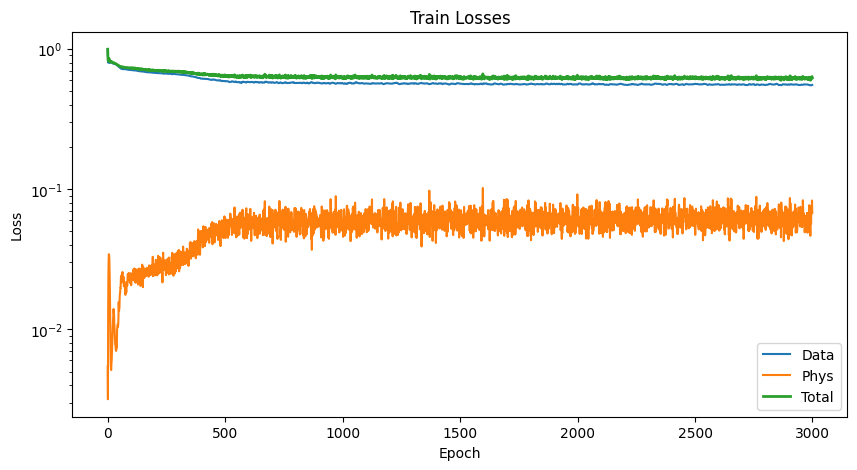

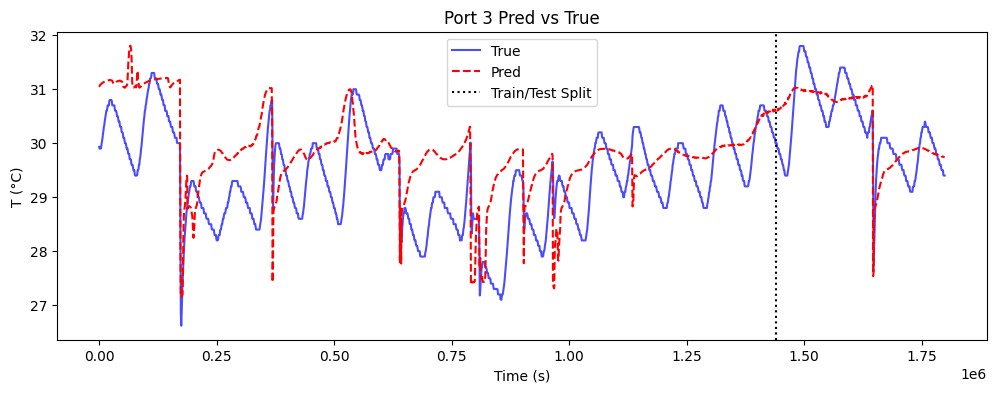

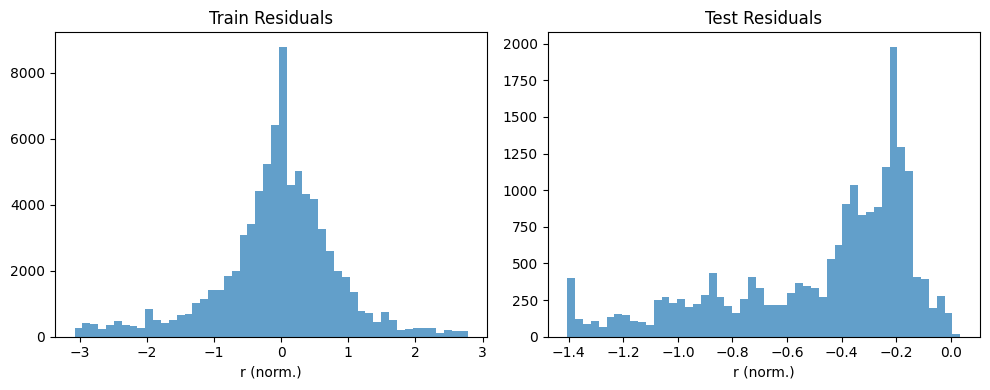

Saved to pinn_port3_split.pt


,timestamp,w,T_true,T_pred
0,2024-12-10 12:15:00,0.274228,28.30,29.258419
1,2024-12-10 12:30:00,0.273956,28.30,29.254354
2,2024-12-10 12:45:00,0.273917,28.32,29.253954
3,2024-12-10 13:00:00,0.273801,28.40,29.253052
4,2024-12-10 13:15:00,0.273529,28.40,29.252604


Test preds saved as predictions_port{PORT}_test.csv


In [3]:
# Fixed PINN Notebook: Train/Test Split + Residual Eval (No no_grad for Physics)
# Bug Fix: Residual computation needs grad_fn—compute without no_grad, detach for metrics.
# Run for Port 1 (change PORT for 2/3). Outputs train/test metrics, residuals on both.

import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.autograd import grad
from sklearn.metrics import mean_absolute_error, mean_squared_error

# ---------------------- User Settings ----------------------
DATA_PATH = "/kaggle/input/pinn-soil/SoilTemp_Engineering_Completedataset.xlsx"
PORT = 3  # 1, 2, or 3
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)

# Hyperparams
N_EPOCHS = 3000
N_COLLOC = 2000
LR = 1e-3
LAMBDA_PHYS = 1.0
USE_LBFGS = True
PRINT_INTERVAL = 100
SPLIT_RATIO = 0.8  # 80% train, 20% test

# -----------------------------------------------------------
p = Path(DATA_PATH)
if not p.exists():
    raise FileNotFoundError(f"{DATA_PATH} not found. CWD: {os.getcwd()}")

# Robust Loader (unchanged)
with open(p, "rb") as f:
    head = f.read(512)
is_zip = head.startswith(b'PK')
if is_zip:
    print("Detected Excel — reading with pd.read_excel()")
    df = pd.read_excel(p)
else:
    print("Detected CSV — robust read")
    encodings_try = ["utf-8", "utf-8-sig", "utf-16", "latin1", "cp1252"]
    df = None
    for enc in encodings_try:
        try:
            df_try = pd.read_csv(p, encoding=enc)
            df = df_try; print(f"CSV with {enc}"); break
        except: continue
    if df is None: df = pd.read_csv(p, encoding="latin1")

print("Columns preview:", df.columns.tolist()[:20])
display(df.head())

# Find timestamp
ts_col = next((c for c in df.columns if isinstance(c, str) and ('timestamp' in c.lower() or 'time' in c.lower())), df.columns[0])
print("Using timestamp:", ts_col)
other_cols = [c for c in df.columns if c != ts_col]
if len(other_cols) < 9:
    try:
        if is_zip: df = pd.read_excel(p, header=1)
        else: df = pd.read_csv(p, header=1, encoding="latin1")
        print("Re-read with header=1")
        display(df.head()); ts_col = df.columns[0]; other_cols = [c for c in df.columns if c != ts_col]
    except: pass

# Numeric conversion & clean
num_df = df[[ts_col] + other_cols].copy()
for c in other_cols: num_df[c] = pd.to_numeric(num_df[c], errors='coerce')
if len(other_cols) < 9: raise ValueError(f"Need 9+ cols after ts; found {len(other_cols)}")
num_df = num_df.dropna(subset=other_cols[:9]).reset_index(drop=True)
print(f"Clean rows: {num_df.shape[0]}")

# Port columns
cols = num_df.columns.tolist()
port_offsets = {1: (1,2,3), 2: (4,5,6), 3: (7,8,9)}
wc_col, t_col = cols[port_offsets[PORT][0]], cols[port_offsets[PORT][1]]
print(f"Port {PORT}: WC={wc_col}, T={t_col}")

# Parse ts
def parse_timestamps(series):
    try: ts = pd.to_datetime(series, errors='coerce')
    except: ts = pd.to_datetime(series, errors='coerce')
    if ts.isna().any():
        ts2 = pd.to_datetime(series, format="%d-%m-%Y %H:%M", errors='coerce')
        if ts2.notna().sum() > ts.notna().sum(): ts = ts2
    if ts.isna().any(): ts = pd.to_datetime(series, dayfirst=True, errors='coerce')
    if ts.isna().any(): raise ValueError("TS parse failed")
    seconds = (ts - ts.min()).dt.total_seconds().astype(float)
    return seconds, ts

t_seconds, tseries_all = parse_timestamps(num_df[cols[0]])
wc = pd.to_numeric(num_df[wc_col], errors='coerce')
T = pd.to_numeric(num_df[t_col], errors='coerce')
valid_mask = (~np.isnan(t_seconds)) & (~np.isnan(wc)) & (~np.isnan(T))
t_seconds = pd.Series(t_seconds)[valid_mask].reset_index(drop=True)
wc = wc[valid_mask].reset_index(drop=True)
T = T[valid_mask].reset_index(drop=True)
t_np = np.array(t_seconds, dtype=float)
w_np = np.array(wc, dtype=float)
T_np = np.array(T, dtype=float)
print(f"Prepared: {len(t_np)} samples for Port {PORT}")

# ----------------- Train/Test Split (Chronological) -----------------
split_idx = int(SPLIT_RATIO * len(t_np))
t_train_np, t_test_np = t_np[:split_idx], t_np[split_idx:]
w_train_np, w_test_np = w_np[:split_idx], w_np[split_idx:]
T_train_np, T_test_np = T_np[:split_idx], T_np[split_idx:]

print(f"Train: {len(t_train_np)} pts ({SPLIT_RATIO*100:.0f}%), Test: {len(t_test_np)} pts")

# Normalize ON TRAIN ONLY
t_mean, t_std = t_train_np.mean(), t_train_np.std() + 1e-8
w_mean, w_std = w_train_np.mean(), w_train_np.std() + 1e-8
T_mean, T_std = T_train_np.mean(), T_train_np.std() + 1e-8

t_train_norm = (t_train_np - t_mean) / t_std
w_train_norm = (w_train_np - w_mean) / w_std
T_train_norm = (T_train_np - T_mean) / T_std

t_test_norm = (t_test_np - t_mean) / t_std
w_test_norm = (w_test_np - w_mean) / w_std
T_test_norm = (T_test_np - T_mean) / T_std

# Tensors (requires_grad=True for t_train/t_test for residuals)
t_train = torch.tensor(t_train_norm.reshape(-1,1), dtype=torch.float32, device=DEVICE, requires_grad=True)
w_train = torch.tensor(w_train_norm.reshape(-1,1), dtype=torch.float32, device=DEVICE)
T_train = torch.tensor(T_train_norm.reshape(-1,1), dtype=torch.float32, device=DEVICE)

t_test = torch.tensor(t_test_norm.reshape(-1,1), dtype=torch.float32, device=DEVICE, requires_grad=True)
w_test = torch.tensor(w_test_norm.reshape(-1,1), dtype=torch.float32, device=DEVICE)
T_test = torch.tensor(T_test_norm.reshape(-1,1), dtype=torch.float32, device=DEVICE)

# Collocations from TRAIN domain
def sample_collocation(nc):
    t_s = np.random.uniform(t_train_norm.min(), t_train_norm.max(), (nc,1))
    w_s = np.random.uniform(w_train_norm.min(), w_train_norm.max(), (nc,1))
    return (torch.tensor(t_s, dtype=torch.float32, device=DEVICE, requires_grad=True),
            torch.tensor(w_s, dtype=torch.float32, device=DEVICE))

# Save scalers
np.savez('scalers.npz', t_mean=t_mean, t_std=t_std, w_mean=w_mean, w_std=w_std, T_mean=T_mean, T_std=T_std)

# ----------------- Model -----------------
class PINN_T(nn.Module):
    def __init__(self, in_dim=2, hidden=64, layers=4):
        super().__init__()
        seq = [nn.Linear(in_dim, hidden), nn.Tanh()]
        for _ in range(layers-1): seq += [nn.Linear(hidden, hidden), nn.Tanh()]
        seq.append(nn.Linear(hidden,1))
        self.net = nn.Sequential(*seq)
        for m in self.net:
            if isinstance(m, nn.Linear): nn.init.xavier_normal_(m.weight); nn.init.zeros_(m.bias)
    def forward(self, t, w): return self.net(torch.cat([t, w], dim=1))

class ParamKTeq(nn.Module):
    def __init__(self): super().__init__(); self.k0 = nn.Parameter(torch.tensor(0.1)); self.k1 = nn.Parameter(torch.tensor(0.0)); self.a = nn.Parameter(torch.tensor(0.0)); self.b = nn.Parameter(torch.tensor(0.0))
    def k_of_w(self, w): return self.k0 + self.k1 * w
    def Teq_of_w(self, w): return self.a + self.b * w

pinn = PINN_T().to(DEVICE)
phys = ParamKTeq().to(DEVICE)
print("Params count:", sum(p.numel() for p in pinn.parameters()) + sum(p.numel() for p in phys.parameters()))

# Loss & Optimizer
mse = nn.MSELoss()
optimizer = torch.optim.Adam(list(pinn.parameters()) + list(phys.parameters()), lr=LR)
history = {"L_data": [], "L_phys": [], "L_total": []}

def physics_residual(t_colloc, w_colloc):
    T_hat = pinn(t_colloc, w_colloc)
    dTdt = grad(T_hat, t_colloc, grad_outputs=torch.ones_like(T_hat), create_graph=True)[0]
    k_w = phys.k_of_w(w_colloc); Teq_w = phys.Teq_of_w(w_colloc)
    return dTdt + k_w * (T_hat - Teq_w)

# ----------------- Training on TRAIN -----------------
print("Training on", DEVICE)
for ep in range(N_EPOCHS):
    optimizer.zero_grad()
    T_pred_train = pinn(t_train, w_train)
    L_data = mse(T_pred_train, T_train)
    t_c, w_c = sample_collocation(N_COLLOC)
    r_c = physics_residual(t_c, w_c)
    L_phys = torch.mean(r_c**2)
    L_total = L_data + LAMBDA_PHYS * L_phys
    L_total.backward()
    optimizer.step()
    history["L_data"].append(L_data.item()); history["L_phys"].append(L_phys.item()); history["L_total"].append(L_total.item())
    if (ep % PRINT_INTERVAL == 0) or (ep == N_EPOCHS-1):
        print(f"Epoch {ep+1}/{N_EPOCHS} L_data={L_data.item():.3e} L_phys={L_phys.item():.3e} L_total={L_total.item():.3e}")

# LBFGS on TRAIN
if USE_LBFGS:
    print("L-BFGS fine-tune...")
    lbfgs = torch.optim.LBFGS(list(pinn.parameters()) + list(phys.parameters()), lr=1.0, max_iter=500, history_size=50)
    def closure(): lbfgs.zero_grad(); Tpred = pinn(t_train, w_train); Ld = mse(Tpred, T_train); tc, wc = sample_collocation(N_COLLOC); Lp = torch.mean(physics_residual(tc, wc)**2); Lt = Ld + LAMBDA_PHYS * Lp; Lt.backward(); return Lt
    lbfgs.step(closure)
    with torch.no_grad(): Ld_final = mse(pinn(t_train, w_train), T_train).item()
    tc_f, wc_f = sample_collocation(N_COLLOC); Lp_final = torch.mean(physics_residual(tc_f, wc_f)**2).item()
    print(f"L-BFGS: L_data={Ld_final:.3e}, L_phys={Lp_final:.3e}")

# ----------------- Evaluation: TRAIN & TEST -----------------
pinn.eval(); phys.eval()

# Predictions (with no_grad for efficiency)
with torch.no_grad():
    T_pred_train_norm = pinn(t_train, w_train).cpu().numpy()
    T_pred_train = T_pred_train_norm * T_std + T_mean
    t_train_plot = t_train.detach().cpu().numpy() * t_std + t_mean

    T_pred_test_norm = pinn(t_test, w_test).cpu().numpy()
    T_pred_test = T_pred_test_norm * T_std + T_mean
    t_test_plot = t_test.detach().cpu().numpy() * t_std + t_mean

# Metrics
train_mae = mean_absolute_error(T_train_np[:split_idx], T_pred_train.flatten())
train_rmse = np.sqrt(mean_squared_error(T_train_np[:split_idx], T_pred_train.flatten()))
test_mae = mean_absolute_error(T_test_np, T_pred_test.flatten())
test_rmse = np.sqrt(mean_squared_error(T_test_np, T_pred_test.flatten()))

print(f"\nTrain MAE/RMSE: {train_mae:.4f}/{train_rmse:.4f} °C")
print(f"Test MAE/RMSE: {test_mae:.4f}/{test_rmse:.4f} °C")

# Physics Residuals (NO no_grad; detach for metrics)
r_train = physics_residual(t_train, w_train).detach()
mean_abs_r_train = torch.mean(torch.abs(r_train)).item() * T_std / t_std  # Denorm approx °C/h
r_test = physics_residual(t_test, w_test).detach()
mean_abs_r_test = torch.mean(torch.abs(r_test)).item() * T_std / t_std
print(f"Train Mean |r| (denorm approx.): {mean_abs_r_train:.4f} °C/h")
print(f"Test Mean |r| (denorm approx.): {mean_abs_r_test:.4f} °C/h")

# Learned Params
k0, k1 = phys.k0.item(), phys.k1.item()
a, b = phys.a.item(), phys.b.item()
print(f"\nParams (norm.): k(w)={k0:.6e} + {k1:.6e} w; T_eq(w)={a:.6e} + {b:.6e} w")

# ----------------- Plots -----------------
# Losses
plt.figure(figsize=(10,5)); plt.semilogy(history["L_data"], label="Data"); plt.semilogy(history["L_phys"], label="Phys"); plt.semilogy(history["L_total"], label="Total", lw=2)
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.title("Train Losses"); plt.show()

# Time Series (Train + Test)
Nplot = min(2000, len(t_train_plot) + len(t_test_plot))
t_full_plot = np.concatenate([t_train_plot.flatten(), t_test_plot.flatten()])
T_true_full = np.concatenate([T_train_np[:split_idx], T_test_np])
T_pred_full = np.concatenate([T_pred_train.flatten(), T_pred_test.flatten()])
sort_idx = np.argsort(t_full_plot)
plt.figure(figsize=(12,4))
plt.plot(t_full_plot[sort_idx][:Nplot], T_true_full[sort_idx][:Nplot], 'b-', label="True", alpha=0.7)
plt.plot(t_full_plot[sort_idx][:Nplot], T_pred_full[sort_idx][:Nplot], 'r--', label="Pred")
plt.axvline(t_full_plot[sort_idx][int(SPLIT_RATIO * Nplot)], color='k', ls=':', label="Train/Test Split")
plt.xlabel("Time (s)"); plt.ylabel("T (°C)"); plt.legend(); plt.title(f"Port {PORT} Pred vs True"); plt.show()

# Residuals Plot (Train vs Test)
plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.hist(r_train.cpu().numpy().flatten(), bins=50, alpha=0.7, label="Train"); plt.title("Train Residuals"); plt.xlabel("r (norm.)")
plt.subplot(1,2,2); plt.hist(r_test.cpu().numpy().flatten(), bins=50, alpha=0.7, label="Test"); plt.title("Test Residuals"); plt.xlabel("r (norm.)")
plt.tight_layout(); plt.show()

# Save
SAVE_PATH = f"pinn_port{PORT}_split.pt"
torch.save({'pinn': pinn.state_dict(), 'phys': phys.state_dict(), 'scalers': {'t_mean': t_mean, 't_std': t_std, 'w_mean': w_mean, 'w_std': w_std, 'T_mean': T_mean, 'T_std': T_std}}, SAVE_PATH)
print(f"Saved to {SAVE_PATH}")

# Test DF
test_df = pd.DataFrame({'timestamp': tseries_all.iloc[split_idx:].reset_index(drop=True), 'w': w_test_np, 'T_true': T_test_np, 'T_pred': T_pred_test.flatten()})
display(test_df.head())
test_df.to_csv(f'predictions_port{PORT}_test.csv', index=False)
print("Test preds saved as predictions_port{PORT}_test.csv")